Historical estimation: Glivenko-Cantelli theorem - coding (Homework)

Reading material: It is recommended that I study Historical estimation.

Code reference: Become familiar with the script s_glivenko_cantelli which illustrates the
Glivenko-Cantelli theorem.

Consider an i.i.d  Et' which is uniformly distributed on the unit interval Et ~ Unif([0,1]).

Prepare environment

In [1]:
import numpy as np
from scipy.stats import uniform
from seaborn.distributions import ECDF
from seaborn import barplot, lineplot
from matplotlib.pyplot import show

Task 1

Generate a set t_bar = 10 observations.
Compare the historical pdf as represented by a normalized histogram, with true uniform pdf fE
and compare the historical cdf F_hat_Hist with the true uniform cdf FE.

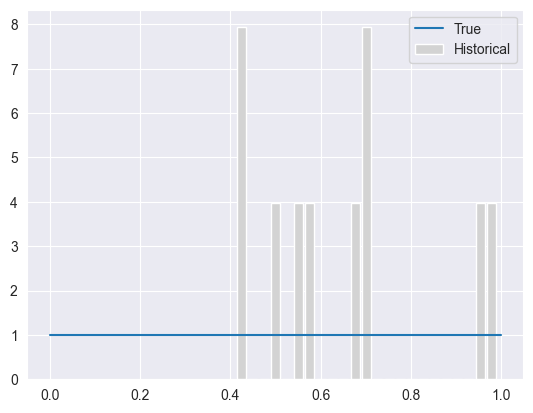

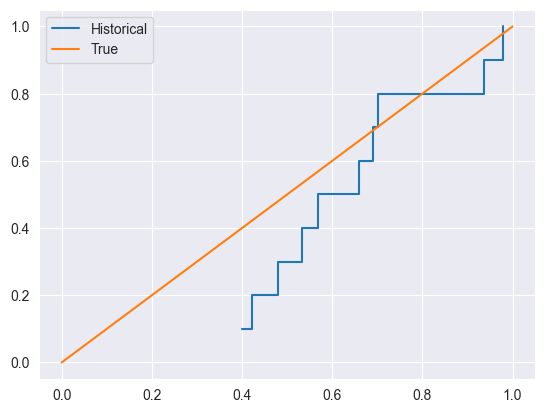

In [3]:
################### inputs ###################
# lower bound of uniform distribution
a = 0
# upper bound of uniform distribution
b = 1
# number of observation
t_bar = 10
# number of bins for histogram
n_bins = 23
# number of grid points for cdf
k_bar = 500
#############################################

# uniform sample
eps = uniform.rvs(loc=a, scale=b - a, size=t_bar)

# uniform probabilities: each observation gets weight 1/t_bar
p = np.ones(t_bar)/t_bar

# historical
# pdf: normalized histogram (smoothed into bins)
# density=True divides each bin's probability by the bin width, so the AREA is 1
# and the bars are on the same scale as the true pdf (height 1 for Unif[0, 1])
pdf_hist_eps, x_grid_pdf = np.histogram(eps, bins=n_bins, weights=p, density=True)
# cdf: historical cdf F(x) = sum_t p_t 1{eps_t <= x}
cdf_hist_eps, x_grid_cdf = ECDF('proportion')(eps, weights=p)

# true uniform
# pdf
pdf_eps = lambda x: uniform.pdf(x, loc=a, scale=b - a)
# cdf
cdf_eps = lambda x: uniform.cdf(x, loc=a, scale=b - a)


############################# PLOTS #############################
# Grid of points
# Mines
x = np.linspace(a, b, k_bar + 1)
# ARPM version commenting out as not covering all way
# x = np.linspace(0, max(eps), k_bar + 1)

#historical pdf and true uniform pdf
# bin_mid = (x_grid_pdf[:-1] + x_grid_pdf[1:]) / 2
# Mines
# barplot(x=bin_mid, y=pdf_hist_eps, native_scale=True, color='lightgray', label='Historical')
# ARPM's implementation which I think is cutting off too soon
barplot(x=x_grid_pdf[1:], y=pdf_hist_eps, native_scale=True, color='lightgray', label='Historical')
# lineplot
lineplot(x=x, y=pdf_eps(x), label='True')
show();

# historical cdf and true uniform cdf
# -> lineplot(x = x_grid_cdf, y=cdf_hist_eps, label='Historical')
# I have updated this as I believe the historical cdf should be by definition a 'Staircase'
# flat between observations, but jumping by p_t = 1/t_bar at each one
#I have implemented drawstyle='steps-post' as it draws it as a step function.
lineplot(x = x_grid_cdf, y=cdf_hist_eps, drawstyle='steps-post', label='Historical')
lineplot(x=x, y=cdf_eps(x), label='True')
show();

Cross-check (not part of the graded answer): my own historical cdf

ECDF is a private seaborn class, so it could move in the future release

Below is my from-scratch version of the equation 17.24, it returns exactly the same (cdf, grid) pair.
It also returns the Glivenko-Cantelli distance supx|F_hat_Hist_E(x) - F_E(x)|.

In [4]:
def ecdf(eps, weights=None):
    """Historical / HFP cdf
    This outputs the same as Seaborn's ECDF('proportion')(eps, weights=...):
    (cdf values, grid) where grid = sorted data with -inf in front.
    """
    eps = np.asarray(eps)
    w = np.ones(len(eps)) if weights is None else np.asarray(weights)
    order = np.argsort(eps)
    grid = np.r_[-np.inf, eps[order]]
    cdf = np.r_[0.0, np.cumsum(w[order])] / w.sum()
    return cdf, grid

def sup_distance(eps, true_cdf):
    """sup_x |F_hist(x) - F(x) (equation 17.26).
    The largest gap sits just before or just at one of the staircase's jumps,
    so only those points are checked.
    """
    cdf, grid = ecdf(eps)
    F = true_cdf(grid[1:])
    return float(np.max(np.maximum(np.abs(cdf[1:] - F), np.abs(cdf[:-1] - F))))

own_cdf, own_grid = ecdf(eps, weights=p)
assert np.allclose(own_cdf, cdf_hist_eps) and np.array_equal(own_grid, x_grid_cdf)
print("Own ecdf matches seaborn's ECDF exactly")

Own ecdf matches seaborn's ECDF exactly


Run the same test in Task 1.  but setting t_bar = 1,000.
Compare the outputs with the ones in Task 1 and formalize the theoretical result behind. (max 30 words)

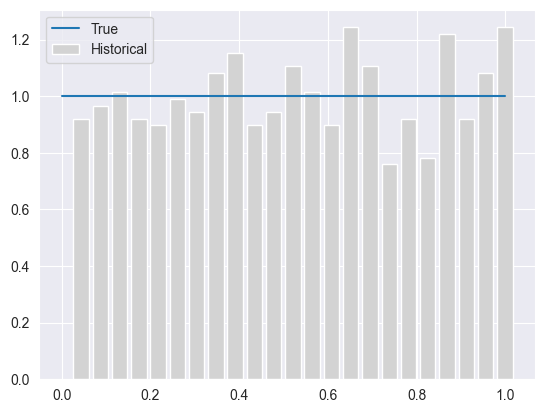

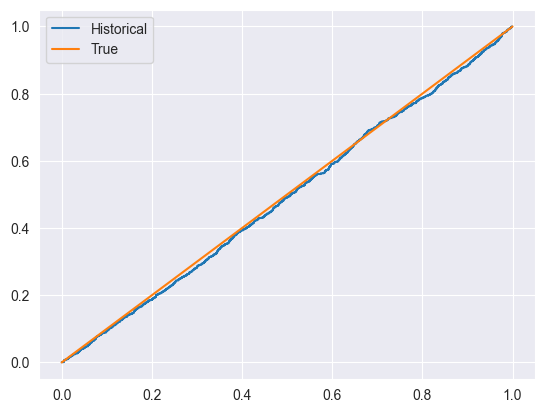

t_bar = 1000: sup|F_hist -F| = 0.021


In [5]:
# number of observation, changed from 10 in Task 1
t_bar = 1000

# uniform sample
eps = uniform.rvs(loc=a, scale=b - a, size=t_bar)
# uniform probabilities: each observation gets weight 1/t_bar
p = np.ones(t_bar)/t_bar

# historical
# pdf: normalized histogram (smoothed into bins)
# same as Task 1
pdf_hist_eps, x_grid_pdf = np.histogram(eps, bins=n_bins, weights=p, density=True)
# cdf: historical cdf F(x) = sum_t p_t 1{eps_t <= x}
cdf_hist_eps, x_grid_cdf = ECDF('proportion')(eps, weights=p)

# true uniform
# pdf
pdf_eps = lambda x: uniform.pdf(x, loc=a, scale=b - a)
# cdf
cdf_eps = lambda x: uniform.cdf(x, loc=a, scale=b - a)


############################# PLOTS #############################
# Grid of points
# Mines, showing full support as in Task 1
x = np.linspace(a, b, k_bar + 1)

#historical pdf and true uniform pdf
# Mines
barplot(x=x_grid_pdf[1:], y=pdf_hist_eps, native_scale=True, color='lightgray', label='Historical')
lineplot(x=x, y=pdf_eps(x), label='True')
show();

# historical cdf and true uniform cdf
# -> lineplot(x = x_grid_cdf, y=cdf_hist_eps, label='Historical')
# I have updated this as I believe the historical cdf should be by definition a 'Staircase'
# flat between observations, but jumping by p_t = 1/t_bar at each one
#I have implemented drawstyle='steps-post' as it draws it as a step function.
lineplot(x = x_grid_cdf, y=cdf_hist_eps, drawstyle='steps-post', label='Historical')
# Task 1
lineplot(x=x, y=cdf_eps(x), label='True')
show();

print(f"t_bar = {t_bar}: sup|F_hist -F| = {sup_distance(eps, cdf_eps):.3f}")

Answer:
With t_bar = 1,000 the histogram and cdf track the truth farmore closely than with t_bar = 10.
Glivenko-Cantelli: for i.i.d
$\varepsilon_t$, $\sup_x|\hat{F}^{Hist}_{\varepsilon}(x)-F_{\varepsilon}(x)|\to 0$ almost surely as $\bar{t}\to\infty$.